load Dataset using pandas lib

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
df = pd.read_excel('/content/drive/MyDrive/Data_Train.xlsx')

In [ ]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [ ]:
df.shape

(10683, 11)

In [ ]:
df.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


checking for missing values and droping it

In [ ]:
df.isnull().sum()

,0
Airline,0
Date_of_Journey,0
Source,0
Destination,0
Route,1
Dep_Time,0
Arrival_Time,0
Duration,0
Total_Stops,1
Additional_Info,0


In [ ]:
df.dropna(inplace=True)

In [ ]:
df.shape

(10682, 11)

now checking for duplicates and droping it

In [ ]:
df.duplicated().sum()

np.int64(220)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Price
count,10462.000000
mean,9026.790289
std,4624.849541
min,1759.000000
25%,5224.000000
50%,8266.000000
75%,12344.750000
max,79512.000000


In [ ]:
df["Airline"].value_counts()

,count
Airline,
Jet Airways,3700
IndiGo,2043
Air India,1694
Multiple carriers,1196
SpiceJet,815
Vistara,478
Air Asia,319
GoAir,194
Multiple carriers Premium economy,13


graphical representation using matplot library

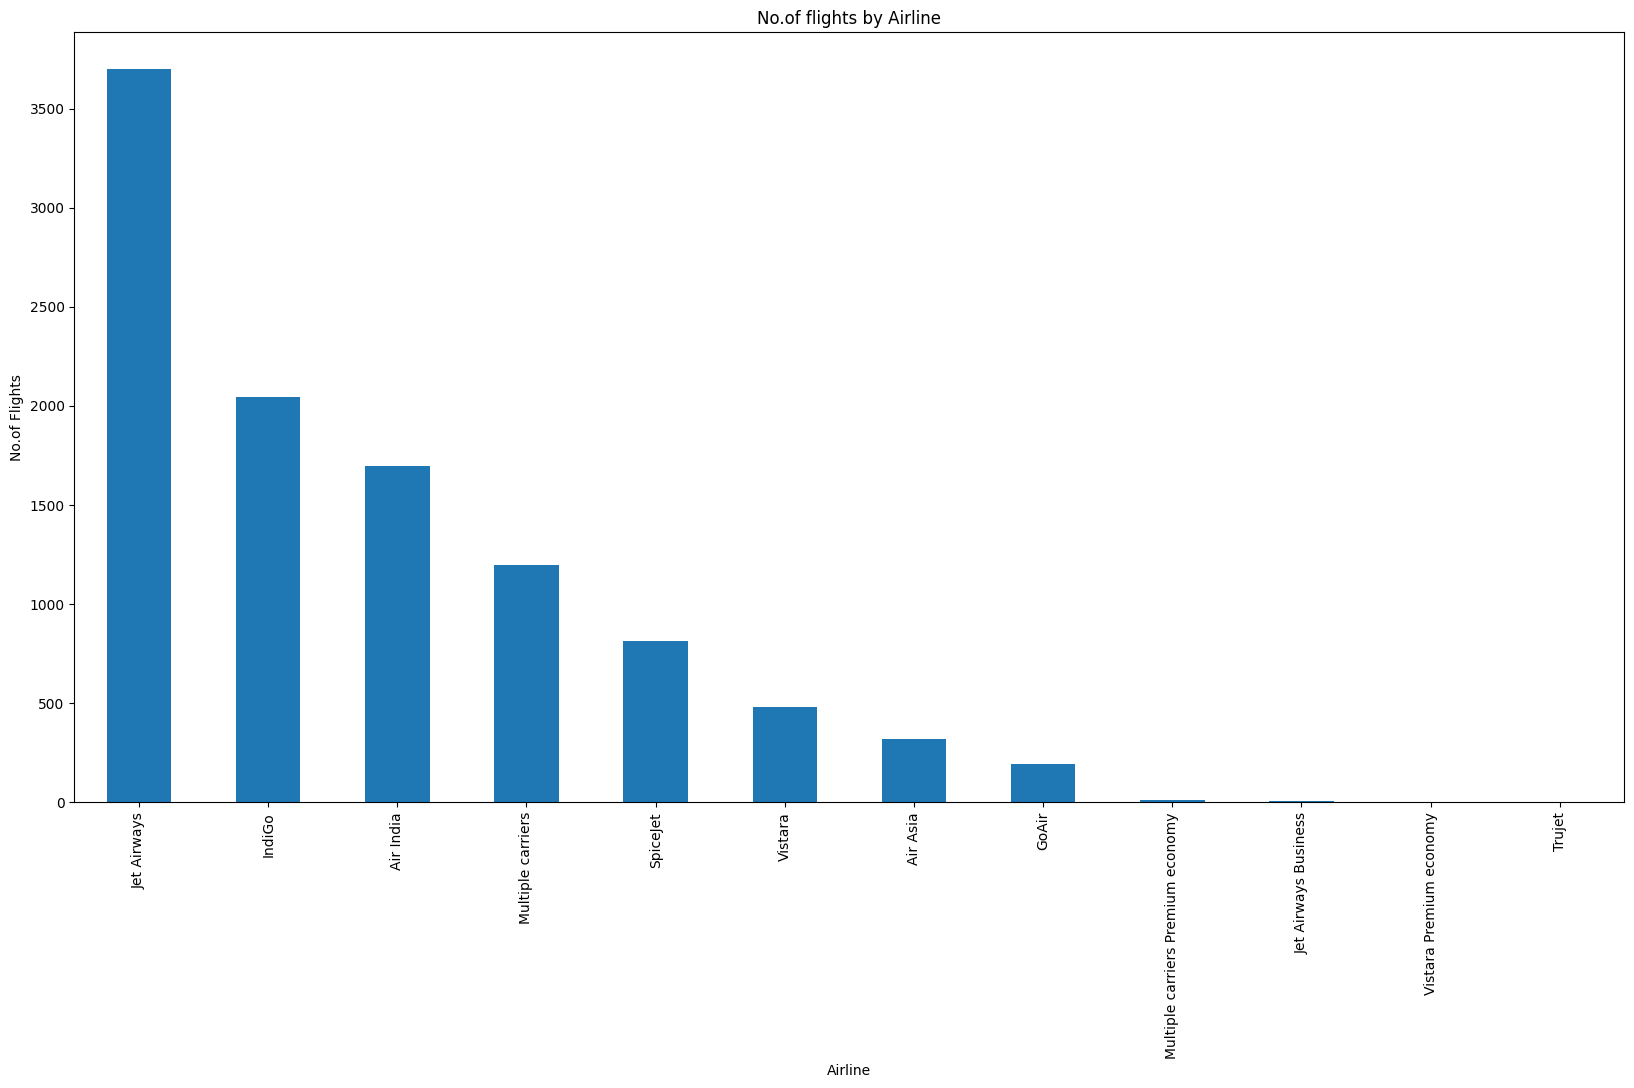

In [ ]:
import matplotlib.pyplot as plt
df["Airline"].value_counts().plot(kind="bar",figsize=(20,10))
plt.title("No.of flights by Airline")
plt.xlabel("Airline")
plt.ylabel("No.of Flights")
plt.show()

here plt is known as alias of that library,
df is known as entire dataset and value _counts() will count the airlines no.of flights from dataset, (20,10) means tells that plot a bar graph with height 20 and width 10
plt.title says that title for that bargraph and pltxlabel and ylabel means names for that xlabel and y label
plt.show means it will displays the total bar graph

Histogram

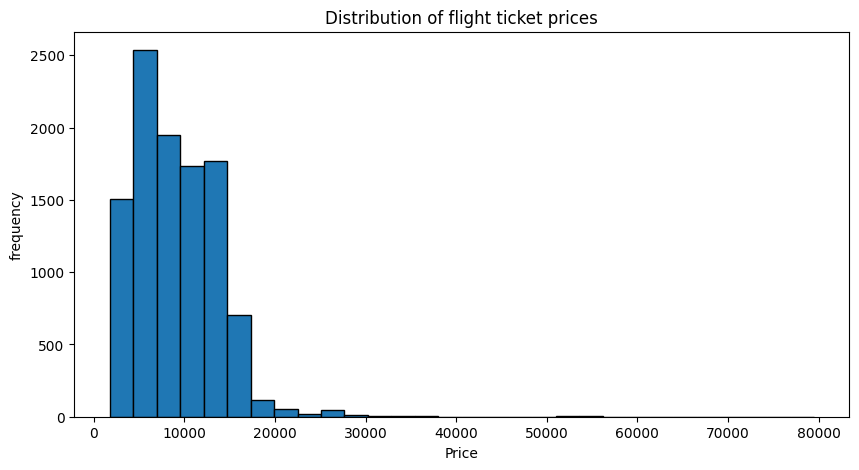

In [ ]:
plt.figure(figsize=(10,5))
plt.hist(df["Price"],bins = 30, edgecolor="black")
plt.title("Distribution of flight ticket prices")
plt.xlabel("Price")
plt.ylabel("frequency")
plt.show()

Boxplot for the prices

boxplot contains mainly four components
1. Lower whiskers
2.box
3. median line
4. upper whisker
5. outliers

lower whiskers: starting prices for the dataset
box: middle part of the flight prices like in the below graph 50% below 20k
orange line: median for that data exactly 8266
upper whisker: ending
outliers: unusual values from the dataset

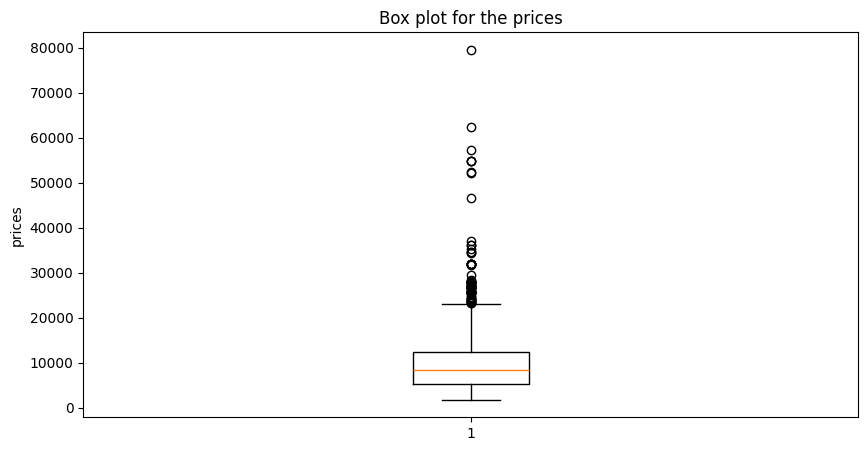

In [ ]:
plt.figure(figsize=(10,5))
plt.boxplot(df["Price"])
plt.title("Box plot for the prices")
plt.ylabel("prices")
plt.show()

In [ ]:
df["Journey_date"]=pd.to_datetime(df["Date_of_Journey"]).dt.date
df["Journey_day"]=pd.to_datetime(df["Date_of_Journey"]).dt.day
df["Journey_month"]=pd.to_datetime(df["Date_of_Journey"]).dt.month

/tmp/ipykernel_1256/238936957.py:1: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Journey_date"]=pd.to_datetime(df["Date_of_Journey"]).dt.date
/tmp/ipykernel_1256/238936957.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Journey_day"]=pd.to_datetime(df["Date_of_Journey"]).dt.day
/tmp/ipykernel_1256/238936957.py:3: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Journey_month"]=pd.to_datetime(df["Date_of_Journey"]).dt.month


In [ ]:
df[["Journey_date","Journey_day","Journey_month"]].head()

,Journey_date,Journey_day,Journey_month
0,2019-03-24,24,3
1,2019-05-01,1,5
2,2019-06-09,9,6
3,2019-05-12,12,5
4,2019-03-01,1,3


In [ ]:
df.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price', 'Journey_date', 'Journey_day',
       'Journey_month'],
      dtype='object')

In [ ]:
df.drop("DAte_of_Journey", axis=1, inplace=True)

KeyError: "['DAte_of_Journey'] not found in axis"

In [ ]:
df["Dep_Hour"]=pd.to_datetime(df["Dep_Time"]).dt.hour
df["Dep_Min"]=pd.to_datetime(df["Dep_Time"]).dt.minute

/tmp/ipykernel_1256/2955936554.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Dep_Hour"]=pd.to_datetime(df["Dep_Time"]).dt.hour
/tmp/ipykernel_1256/2955936554.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Dep_Min"]=pd.to_datetime(df["Dep_Time"]).dt.minute


In [ ]:
df.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price', 'Journey_date', 'Journey_day',
       'Journey_month', 'Dep_Hour', 'Dep_Min'],
      dtype='object')

In [ ]:
df[["Dep_Time","Dep_Hour","Dep_Min"]].head()

,Dep_Time,Dep_Hour,Dep_Min
0,22:20,22,20
1,05:50,5,50
2,09:25,9,25
3,18:05,18,5
4,16:50,16,50


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10462 entries, 0 to 10682
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10462 non-null  object
 1   Date_of_Journey  10462 non-null  object
 2   Source           10462 non-null  object
 3   Destination      10462 non-null  object
 4   Route            10462 non-null  object
 5   Dep_Time         10462 non-null  object
 6   Arrival_Time     10462 non-null  object
 7   Duration         10462 non-null  object
 8   Total_Stops      10462 non-null  object
 9   Additional_Info  10462 non-null  object
 10  Price            10462 non-null  int64 
 11  Journey_date     10462 non-null  object
 12  Journey_day      10462 non-null  int32 
 13  Journey_month    10462 non-null  int32 
 14  Dep_Hour         10462 non-null  int32 
 15  Dep_Min          10462 non-null  int32 
dtypes: int32(4), int64(1), object(11)
memory usage: 1.2+ MB


In [ ]:
df["Arrival_Time"].head(10)

,Arrival_Time
0,01:10 22 Mar
1,13:15
2,04:25 10 Jun
3,23:30
4,21:35
5,11:25
6,10:25 13 Mar
7,05:05 02 Mar
8,10:25 13 Mar
9,19:15


In [ ]:
df["Arrival_Time"]=df["Arrival_Time"].str.split(" ").str[0]
df["Arrival_Time"].head(10)

,Arrival_Time
0,01:10
1,13:15
2,04:25
3,23:30
4,21:35
5,11:25
6,10:25
7,05:05
8,10:25
9,19:15


In [ ]:
df["Arrival_Hour"] = pd.to_datetime(
    df["Arrival_Time"], format="%H:%M"
).dt.hour
df["Arrival_Min"] = pd.to_datetime(
    df["Arrival_Time"], format="%H:%M"
).dt.minute
df[["Arrival_Time","Arrival_Hour","Arrival_Min"]].head(10)

,Arrival_Time,Arrival_Hour,Arrival_Min
0,01:10,1,10
1,13:15,13,15
2,04:25,4,25
3,23:30,23,30
4,21:35,21,35
5,11:25,11,25
6,10:25,10,25
7,05:05,5,5
8,10:25,10,25
9,19:15,19,15


In [ ]:
df[df["Arrival_Time"].str.len() < 5]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_date,Journey_day,Journey_month,Dep_Hour,Dep_Min,Arrival_Hour,Arrival_Min


In [ ]:
n = int(input("Enter n value:  "))
arr = []
print("Enter elements: ")
for i in range(n):
  arr.append(int(input()))
min_element = arr[0]
max_element = arr[0]
max_difference = arr[1]-arr[0]
for i in range(1,n):
  if arr[i]-min_element>max_difference:
    max_difference = arr[i]-min_element
  if arr[i]>max_element:
    max_element = arr[i]
  if arr[i]<min_element:
    min_element = arr[i]
print(max_difference,min_element,max_element)


Enter n value:  5
Enter elements: 
2
3
5
6
2
4 2 6


In [ ]:
df["Arrival_Time"].dtype
df["Arrival_Time"].head(10)

,Arrival_Time
0,01:10
1,13:15
2,04:25
3,23:30
4,21:35
5,11:25
6,10:25
7,05:05
8,10:25
9,19:15


In [ ]:
df.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price', 'Journey_date', 'Journey_day',
       'Journey_month', 'Dep_Hour', 'Dep_Min', 'Arrival_Hour', 'Arrival_Min'],
      dtype='object')

In [ ]:
df.drop("Arrival_Time",axis=1,inplace=True)
df.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Duration', 'Total_Stops', 'Additional_Info', 'Price',
       'Journey_date', 'Journey_day', 'Journey_month', 'Dep_Hour', 'Dep_Min',
       'Arrival_Hour', 'Arrival_Min'],
      dtype='object')

In [ ]:
df["Duration"].head(10)

,Duration
0,2h 50m
1,7h 25m
2,19h
3,5h 25m
4,4h 45m
5,2h 25m
6,15h 30m
7,21h 5m
8,25h 30m
9,7h 50m


In [ ]:
df["Duration"]=df["Duration"].replace(r"(\d+)h$",r"\1h 0m",regex=True)
df["Duration"].head(20)

,Duration
0,2h 50m
1,7h 25m
2,19h 0m
3,5h 25m
4,4h 45m
5,2h 25m
6,15h 30m
7,21h 5m
8,25h 30m
9,7h 50m


In [ ]:
df["Duration"]=df["Duration"].replace(r"^(\d+)m$",r"\0h 1m",regex=True)
df["Duration"].head(20)

,Duration
0,2h 50m
1,7h 25m
2,19h 0m
3,5h 25m
4,4h 45m
5,2h 25m
6,15h 30m
7,21h 5m
8,25h 30m
9,7h 50m


In [ ]:
df["Duration_Hour"]=df["Duration"].str.split().str[0].str.replace("h","",regex=False).astype(int)


ValueError: invalid literal for int() with base 10: '\x00'

In [ ]:
for i, val in enumerate(df["Duration"]):
    try:
        int(str(val).split()[0].replace("h", ""))
    except:
        print(i, repr(val))

6397 '\x00h 1m'


In [ ]:
df.loc[6474,"Duration"] = "0h 1m"
df.loc[6474,"Duration"]

'0h 1m'

In [ ]:
df["Duration_Hour"]=df["Duration"].str.split().str[0].str.replace("h","",regex=False).astype(int)
df["Duration_Min"]=df["Duration"].str.split().str[1].str.replace("m","",regex=False).astype(int)
df[["Duration","Duration_Hour","Duration_Min"]].head(20)

,Duration,Duration_Hour,Duration_Min
0,2h 50m,2,50
1,7h 25m,7,25
2,19h 0m,19,0
3,5h 25m,5,25
4,4h 45m,4,45
5,2h 25m,2,25
6,15h 30m,15,30
7,21h 5m,21,5
8,25h 30m,25,30
9,7h 50m,7,50


In [ ]:
df.drop("Duration",axis=1,inplace=True)
df.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Total_Stops', 'Additional_Info', 'Price', 'Journey_date',
       'Journey_day', 'Journey_month', 'Dep_Hour', 'Dep_Min', 'Arrival_Hour',
       'Arrival_Min', 'Duration_Hour', 'Duration_Min'],
      dtype='object')

In [ ]:
df["Total_Stops"].value_counts()

,count
Total_Stops,
1 stop,5625
non-stop,3475
2 stops,1318
3 stops,43
4 stops,1


In [ ]:
df["Total_Stops"].isnull().sum()
df[df["Total_Stops"].isnull()]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Total_Stops,Additional_Info,Price,Journey_date,Journey_day,Journey_month,Dep_Hour,Dep_Min,Arrival_Hour,Arrival_Min,Duration_Hour,Duration_Min


In [ ]:
df.dropna(inplace=True)

replace()

In [ ]:
df["Total_Stops"]=df["Total_Stops"].replace({"non-stop":0,"1 stop":1,"2 stops":2,"3 stops":3,"4 stops":4})
df["Total_Stops"]=df["Total_Stops"].astype(int)
df["Total_Stops"].value_counts()

/tmp/ipykernel_1256/3911663550.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Total_Stops"]=df["Total_Stops"].replace({"non-stop":0,"1 stop":1,"2 stops":2,"3 stops":3,"4 stops":4})


,count
Total_Stops,
1,5625
0,3475
2,1318
3,43
4,1


one-Hot code()

In [ ]:
airline = pd.get_dummies(df["Airline"],prefix="Airline",dtype = int)
df = pd.concat([df,airline],axis=1)
#df.drop("Airline",axis=1,inplace=True)
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Total_Stops,Additional_Info,Price,Journey_date,...,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,0,No info,3897,2019-03-24,...,0,1,0,0,0,0,0,0,0,0
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,2,No info,7662,2019-05-01,...,0,0,0,0,0,0,0,0,0,0
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,2,No info,13882,2019-06-09,...,0,0,1,0,0,0,0,0,0,0
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,1,No info,6218,2019-05-12,...,0,1,0,0,0,0,0,0,0,0
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,1,No info,13302,2019-03-01,...,0,1,0,0,0,0,0,0,0,0


In [ ]:
df["Source"].unique()
df["Source"].value_counts()

,count
Source,
Delhi,4345
Kolkata,2860
Banglore,2179
Mumbai,697
Chennai,381


In [ ]:
source = pd.get_dummies(df["Source"],prefix="Source",dtype=int)

In [ ]:
source.head()

,Source_Banglore,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai
0,1,0,0,0,0
1,0,0,0,1,0
2,0,0,1,0,0
3,0,0,0,1,0
4,1,0,0,0,0


In [ ]:
df = pd.concat([df,source],axis=1)
#df.drop("Source",axis=1,inplace=True)
df.head()

,Airline,Date_of_Journey,Destination,Route,Dep_Time,Total_Stops,Additional_Info,Price,Journey_date,Journey_day,...,Source_Banglore,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Source_Banglore,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai
0,IndiGo,24/03/2019,New Delhi,BLR → DEL,22:20,0,No info,3897,2019-03-24,24,...,1,0,0,0,0,1,0,0,0,0
1,Air India,1/05/2019,Banglore,CCU → IXR → BBI → BLR,05:50,2,No info,7662,2019-05-01,1,...,0,0,0,1,0,0,0,0,1,0
2,Jet Airways,9/06/2019,Cochin,DEL → LKO → BOM → COK,09:25,2,No info,13882,2019-06-09,9,...,0,0,1,0,0,0,0,1,0,0
3,IndiGo,12/05/2019,Banglore,CCU → NAG → BLR,18:05,1,No info,6218,2019-05-12,12,...,0,0,0,1,0,0,0,0,1,0
4,IndiGo,01/03/2019,New Delhi,BLR → NAG → DEL,16:50,1,No info,13302,2019-03-01,1,...,1,0,0,0,0,1,0,0,0,0


In [ ]:
df["Destination"].unique()
df["Destination"].value_counts()

,count
Destination,
Cochin,4345
Banglore,2860
Delhi,1265
New Delhi,914
Hyderabad,697
Kolkata,381


In [ ]:
destination = pd.get_dummies(df["Destination"],prefix="Destination",dtype=int)

In [ ]:
df = pd.concat([df,destination],axis=1)
#df.drop("Destination",axis=1,inplace=True)
df.head()

,Airline,Date_of_Journey,Route,Dep_Time,Total_Stops,Additional_Info,Price,Journey_date,Journey_day,Journey_month,...,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Banglore,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,IndiGo,24/03/2019,BLR → DEL,22:20,0,No info,3897,2019-03-24,24,3,...,0,0,0,0,0,0,0,0,0,1
1,Air India,1/05/2019,CCU → IXR → BBI → BLR,05:50,2,No info,7662,2019-05-01,1,5,...,0,0,1,0,1,0,0,0,0,0
2,Jet Airways,9/06/2019,DEL → LKO → BOM → COK,09:25,2,No info,13882,2019-06-09,9,6,...,0,1,0,0,0,1,0,0,0,0
3,IndiGo,12/05/2019,CCU → NAG → BLR,18:05,1,No info,6218,2019-05-12,12,5,...,0,0,1,0,1,0,0,0,0,0
4,IndiGo,01/03/2019,BLR → NAG → DEL,16:50,1,No info,13302,2019-03-01,1,3,...,0,0,0,0,0,0,0,0,0,1


In [ ]:
df["Route"].head()


,Route
0,BLR → DEL
1,CCU → IXR → BBI → BLR
2,DEL → LKO → BOM → COK
3,CCU → NAG → BLR
4,BLR → NAG → DEL


In [ ]:
df["Route"].nunique()

128

In [ ]:
df.drop("Route",axis=1,inplace=True)

In [ ]:
df.columns

Index(['Airline', 'Date_of_Journey', 'Dep_Time', 'Total_Stops',
       'Additional_Info', 'Price', 'Journey_date', 'Journey_day',
       'Journey_month', 'Dep_Hour', 'Dep_Min', 'Arrival_Hour', 'Arrival_Min',
       'Duration_Hour', 'Duration_Min', 'Airline_Air Asia',
       'Airline_Air India', 'Airline_GoAir', 'Airline_IndiGo',
       'Airline_Jet Airways', 'Airline_Jet Airways Business',
       'Airline_Multiple carriers',
       'Airline_Multiple carriers Premium economy', 'Airline_SpiceJet',
       'Airline_Trujet', 'Airline_Vistara', 'Airline_Vistara Premium economy',
       'Source_Banglore', 'Source_Chennai', 'Source_Delhi', 'Source_Kolkata',
       'Source_Mumbai', 'Source_Banglore', 'Source_Chennai', 'Source_Delhi',
       'Source_Kolkata', 'Source_Mumbai', 'Destination_Banglore',
       'Destination_Cochin', 'Destination_Delhi', 'Destination_Hyderabad',
       'Destination_Kolkata', 'Destination_New Delhi'],
      dtype='object')

In [ ]:
df["Additional_Info"].head()
df["Additional_Info"].nunique()

10

In [ ]:
df["Additional_Info"].value_counts()

,count
Additional_Info,
No info,8182
In-flight meal not included,1926
No check-in baggage included,318
1 Long layover,19
Change airports,7
Business class,4
No Info,3
1 Short layover,1
Red-eye flight,1


In [ ]:
df.drop("Additional_Info",axis=1,inplace=True)
df.columns

Index(['Airline', 'Date_of_Journey', 'Dep_Time', 'Total_Stops', 'Price',
       'Journey_date', 'Journey_day', 'Journey_month', 'Dep_Hour', 'Dep_Min',
       'Arrival_Hour', 'Arrival_Min', 'Duration_Hour', 'Duration_Min',
       'Airline_Air Asia', 'Airline_Air India', 'Airline_GoAir',
       'Airline_IndiGo', 'Airline_Jet Airways', 'Airline_Jet Airways Business',
       'Airline_Multiple carriers',
       'Airline_Multiple carriers Premium economy', 'Airline_SpiceJet',
       'Airline_Trujet', 'Airline_Vistara', 'Airline_Vistara Premium economy',
       'Source_Banglore', 'Source_Chennai', 'Source_Delhi', 'Source_Kolkata',
       'Source_Mumbai', 'Source_Banglore', 'Source_Chennai', 'Source_Delhi',
       'Source_Kolkata', 'Source_Mumbai', 'Destination_Banglore',
       'Destination_Cochin', 'Destination_Delhi', 'Destination_Hyderabad',
       'Destination_Kolkata', 'Destination_New Delhi'],
      dtype='object')

In [ ]:
df.dtypes

,0
Airline,object
Date_of_Journey,object
Dep_Time,object
Total_Stops,int64
Price,int64
Journey_date,object
Journey_day,int32
Journey_month,int32
Dep_Hour,int32
Dep_Min,int32


In [ ]:
df.drop(["Date_of_Journey","Dep_Time","Journey_date"],axis=1,inplace=True)

In [ ]:
df.columns.duplicated().sum()

np.int64(5)

In [ ]:
df = df.loc[:,~df.columns.duplicated()]

In [ ]:
df.columns.duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

,0
Airline,object
Total_Stops,int64
Price,int64
Journey_day,int32
Journey_month,int32
Dep_Hour,int32
Dep_Min,int32
Arrival_Hour,int32
Arrival_Min,int32
Duration_Hour,int64


In [ ]:
df.select_dtypes(include="object").columns

Index([], dtype='object')

In [ ]:
df.drop("Airline",axis=1,inplace=True) #run it after above cell

In [ ]:
X = df.drop("Price",axis=1)
y = df["Price"]

In [ ]:
from sklearn.model_selection import train_test_split

X = input colums like airline,routes and more and y = target (price)
test_size=0.2 means 80% training and 20% testing and random_state menas fixes the random split

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=30)

In [ ]:
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(8369, 33) (2093, 33) (8369,) (2093,)


creating random forest model for these because random forest will make different decision trees and combines the predition for example asking 100 travel agents to select price of the flight u will take all suggestions and predicting all like this random forest model works

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_mode is a variable, n_estimators means it creates decision trees, here 100 is the count means 100 decision trees, random state meant by random split

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=30
)

In [ ]:
rf_model.fit(X_train,y_train)

ValueError: could not convert string to float: 'Multiple carriers'

In [ ]:
X_train.select_dtypes(include="object").columns

Index(['Airline'], dtype='object')

In [ ]:
#df.drop("Airline",axis=1,inplace=True)
print(df.columns)

Index(['Total_Stops', 'Price', 'Journey_day', 'Journey_month', 'Dep_Hour',
       'Dep_Min', 'Arrival_Hour', 'Arrival_Min', 'Duration_Hour',
       'Duration_Min', 'Airline_Air Asia', 'Airline_Air India',
       'Airline_GoAir', 'Airline_IndiGo', 'Airline_Jet Airways',
       'Airline_Jet Airways Business', 'Airline_Multiple carriers',
       'Airline_Multiple carriers Premium economy', 'Airline_SpiceJet',
       'Airline_Trujet', 'Airline_Vistara', 'Airline_Vistara Premium economy',
       'Source_Banglore', 'Source_Chennai', 'Source_Delhi', 'Source_Kolkata',
       'Source_Mumbai', 'Destination_Banglore', 'Destination_Cochin',
       'Destination_Delhi', 'Destination_Hyderabad', 'Destination_Kolkata',
       'Destination_New Delhi'],
      dtype='object')


In [ ]:
print(X.columns)

Index(['Airline', 'Total_Stops', 'Journey_day', 'Journey_month', 'Dep_Hour',
       'Dep_Min', 'Arrival_Hour', 'Arrival_Min', 'Duration_Hour',
       'Duration_Min', 'Airline_Air Asia', 'Airline_Air India',
       'Airline_GoAir', 'Airline_IndiGo', 'Airline_Jet Airways',
       'Airline_Jet Airways Business', 'Airline_Multiple carriers',
       'Airline_Multiple carriers Premium economy', 'Airline_SpiceJet',
       'Airline_Trujet', 'Airline_Vistara', 'Airline_Vistara Premium economy',
       'Source_Banglore', 'Source_Chennai', 'Source_Delhi', 'Source_Kolkata',
       'Source_Mumbai', 'Destination_Banglore', 'Destination_Cochin',
       'Destination_Delhi', 'Destination_Hyderabad', 'Destination_Kolkata',
       'Destination_New Delhi'],
      dtype='object')


In [ ]:
X = df.drop("Price",axis=1)
y = df["Price"]

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=30
)

In [ ]:
print(X_train.select_dtypes(include="object").columns)

Index([], dtype='object')


In [ ]:
rf_model.fit(X_train,y_train)

RandomForestRegressor(random_state=30)

In [ ]:
y_pred = rf_model.predict(X_test)

In [ ]:
print(y_pred[:10])

[12585.9505     14679.53        3232.18        8834.74
 13791.165       4011.25       12913.19        9185.41333333
  9502.433       2802.47      ]


In [ ]:
print("Actual Prices: ")
print(y_test.values[:10])
print("\nPredicted Values: ")
print(y_pred[:10])

Actual Prices: 
[10539 13399  3175  8610 10262  4591 13039 13044 13339  2754]

Predicted Values: 
[12585.9505     14679.53        3232.18        8834.74
 13791.165       4011.25       12913.19        9185.41333333
  9502.433       2802.47      ]


In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = mse**0.5
r2 = r2_score(y_test,y_pred)
print("MAE: ",mae)
print("MSE: ",mse)
print("rmse: ",rmse)
print("r2: ",r2)

MAE:  1192.1331161426565
MSE:  4295167.1247759955
rmse:  2072.478498025009
r2:  0.8231438577303122
